# DSA211: Diagnosing and Remedying Nonlinearity in Bike-Sharing Demand Models
## Notebook 07: Post-Hoc Sensitivity Analysis of Weather Polynomial Degree
**Group 2**: Kok Wai Ying, Lee Sin Yang, Lim Wei Lun Marcus, Samuel Teo Yuzhen, Tee Jing Yuan

> **AI Coding Assistant Declaration**:
> In accordance with course guidelines, an AI coding assistant was used strictly for code scaffolding and plotting functions. All modeling decisions, interpretations, and written commentaries are independently authored by group members in the designated sections below (see [`agents.md`](../agents.md)).

> **Status**: This notebook was added **after** Notebook 06 scored the locked test set. It reads the training set only (`data/train_base.csv`); the test set is not read. Notebook 06's selected model, test score and full-data refit are not changed by anything here.

### Planned Steps
- **1. Setup and checks**: rebuild the Notebook 05 CV engine, reproduce the fold MSEs of OLS M4 and the selected LASSO M4 from `data/cv_results_05_regularization.csv`, and check the orthogonal polynomial basis.
- **2. Degree per weather variable (OLS)**: degree 1 to 4 chosen separately for `temp`, `hum`, `windspeed` (64 combinations), compared with the Notebook 04 joint degree 2.
- **3. Ridge and LASSO with weather terms up to degree 4**: written as raw powers and as orthogonal polynomials; $\lambda$ tuned on the Notebook 05 grids.
- **4. Forward-chained tuning**: $\lambda$ chosen from earlier validation months only (as in Notebook 05 Section 6b.5).
- **5. Residuals by weather variable**: out-of-fold residuals binned by temperature, humidity and wind speed, selected LASSO M4 (weather squared) vs. LASSO M4 with orthogonal weather terms up to degree 4.

## 1. Setup and Checks
*Code: Generated by AI Assistant*

The CV engine (`make_estimator`, `n_params`, `fit_predict_count`, `summarise`, `paired_gain`) is copied from Notebook 05: shared expanding-window folds ($k = 8$), $\log(cnt)$ target back-transformed with $\exp(\hat{y} + \hat{\sigma}^2/2)$, count-scale MSE, $\text{CV RMSE} = \sqrt{\text{mean fold MSE}}$. `design(degrees, terms, rows)` builds the M4 design (48 base columns, weather terms, `hr` $\times$ `workingday`) with each weather variable expanded to its own degree. For `terms` = `raw` the weather terms are powers of $x$; for `orthogonal` they are orthogonal polynomials (Section 3), built on `rows`, the training rows of the fold. The selected $\lambda$ is read from `data/notebook06_selection_frozen.json`.

In [1]:
import os
import sys
import json
import warnings
from itertools import product
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from joblib import Parallel, delayed
from sklearn.linear_model import LinearRegression, Ridge, Lasso
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.exceptions import ConvergenceWarning

sys.path.append(os.path.abspath('..'))
from src.data_utils import load_train_base, DATA_DIR
from src.cv_utils import get_cv_splitter, FIRST_VAL_MONTH, LAST_VAL_MONTH

sns.set_style('whitegrid')
warnings.filterwarnings('ignore', category=ConvergenceWarning)

base_df = load_train_base()
TARGET = 'cnt'
# holiday dropped as in Notebooks 03-06 (exact combination of weekday dummies and workingday)
FEATURE_COLS = [c for c in base_df.columns if c not in ['dteday', TARGET, 'holiday']]
HR_COLS = [c for c in FEATURE_COLS if c.startswith('hr_')]
WEATHER = ['temp', 'hum', 'windspeed']
X_base = base_df[FEATURE_COLS].astype(float)
y_all = base_df[TARGET].to_numpy(dtype=float)

cv_splitter = get_cv_splitter(base_df['dteday'])
FOLDS = list(cv_splitter.split(base_df))
K = len(FOLDS)
VAL_MONTHS = [base_df['dteday'].iloc[va].min().strftime('%Y-%m') for _, va in FOLDS]

ALPHA_GRIDS = {'ridge': np.logspace(-4, 4, 41),     # Notebook 05 grids
               'lasso': np.logspace(-5, -0.5, 31)}
with open(DATA_DIR / 'notebook06_selection_frozen.json') as f:
    ALPHA_SELECTED = json.load(f)['specification']['alpha']

print(f"Training rows: {len(base_df):,} | {K} folds ({FIRST_VAL_MONTH} to {LAST_VAL_MONTH}) | selected LASSO alpha = {ALPHA_SELECTED:.6g}")

Training rows: 15,211 | 8 folds (2012-02 to 2012-09) | selected LASSO alpha = 0.00251189


In [2]:
def make_estimator(kind, alpha=None):
    if kind == 'ols':
        return Pipeline([('reg', LinearRegression())])
    reg = Ridge(alpha=alpha) if kind == 'ridge' else Lasso(alpha=alpha, max_iter=20000, precompute=True)
    return Pipeline([('scale', StandardScaler()), ('reg', reg)])


def n_params(est, X_tr, kind):
    if kind == 'ols':
        return np.linalg.matrix_rank(np.column_stack([np.ones(len(X_tr)), X_tr.to_numpy(dtype=float)]))
    if kind == 'ridge':
        return X_tr.shape[1] + 1
    return int(np.count_nonzero(est.named_steps['reg'].coef_)) + 1


def fit_predict_count(kind, alpha, X_tr, y_tr, X_va):
    est = make_estimator(kind, alpha)
    y_fit = np.log(y_tr)
    est.fit(X_tr, y_fit)
    resid = y_fit - est.predict(X_tr)
    sigma2 = float(resid @ resid / (len(y_tr) - n_params(est, X_tr, kind)))
    return np.exp(est.predict(X_va) + sigma2 / 2), est


def summarise(fold_mse):
    m, s = np.mean(fold_mse), np.std(fold_mse, ddof=1)
    return {'cv_mse': m, 'se_mse': s / np.sqrt(len(fold_mse)),
            'cv_rmse': np.sqrt(m), 'se_rmse': (s / np.sqrt(len(fold_mse))) / (2 * np.sqrt(m))}


def paired_gain(fold_a, fold_b):
    # Positive = model B has lower MSE than model A
    d = fold_a - fold_b
    se = d.std(ddof=1) / np.sqrt(len(d))
    return d.mean(), se, (d.mean() / se if se > 0 else np.nan), int((d > 0).sum())


def ortho_basis(x_fit, deg):
    # Orthogonal polynomials of degree 1..deg fitted on x_fit (QR of the Vandermonde matrix, as R's poly()).
    # Returns a function mapping new x to the same basis; columns are mean 0, variance 1, uncorrelated on x_fit.
    m, s = x_fit.mean(), x_fit.std()
    _, R = np.linalg.qr(np.vander((x_fit - m) / s, deg + 1, increasing=True))
    W = np.linalg.inv(R)[:, 1:] * np.sqrt(len(x_fit))
    return lambda x: np.vander((np.asarray(x, dtype=float) - m) / s, deg + 1, increasing=True) @ W


def weather_basis(c, deg, terms, rows):
    # Function mapping x to the deg weather columns of variable c (fitted on training rows `rows`)
    if terms == 'orthogonal':
        return ortho_basis(X_base[c].to_numpy()[rows], deg)
    if terms != 'raw':
        raise ValueError(terms)
    return lambda x: np.column_stack([np.asarray(x, dtype=float) ** d for d in range(1, deg + 1)])


def col_names(c, deg, terms):
    if terms == 'orthogonal':
        return [f'{c}_orth{d}' for d in range(1, deg + 1)]
    return [c] + [f'{c}^{d}' for d in range(2, deg + 1)]


def design(degrees, terms, rows):
    X = X_base.copy()
    for c, deg in zip(WEATHER, degrees):
        B = weather_basis(c, deg, terms, rows)(X_base[c])
        names = col_names(c, deg, terms)
        X[c] = B[:, 0]                       # degree-1 term stays in the base column position
        for j in range(1, deg):
            X[names[j]] = B[:, j]
        X = X.rename(columns={c: names[0]})
    inter = X[HR_COLS].mul(X['workingday'], axis=0)
    inter.columns = [f'{c}:workingday' for c in HR_COLS]
    return pd.concat([X, inter], axis=1)


def cv_folds(kind, alpha, degrees, terms='raw'):
    warnings.filterwarnings('ignore', category=ConvergenceWarning)   # also applies inside joblib workers
    out = []
    for tr, va in FOLDS:
        X = design(degrees, terms, tr)
        pred, _ = fit_predict_count(kind, alpha, X.iloc[tr], y_all[tr], X.iloc[va])
        out.append(np.mean((y_all[va] - pred) ** 2))
    return np.array(out)


# Reference check against the Notebook 05 export used by Notebook 06
export = pd.read_csv(DATA_DIR / 'cv_results_05_regularization.csv')
REF = (2, 2, 2)
ref_ols = cv_folds('ols', None, REF)
ref_lasso = cv_folds('lasso', ALPHA_SELECTED, REF)
assert np.allclose(ref_ols, export.query("model == 'M4 OLS'").sort_values('fold')['mse'], rtol=1e-6)
assert np.allclose(ref_lasso, export.query("model == 'Lasso m4 (min)'").sort_values('fold')['mse'], rtol=1e-4)
print(f"OLS M4 (degree 2,2,2):        CV RMSE {summarise(ref_ols)['cv_rmse']:.2f}  (matches Notebook 05)")
print(f"LASSO M4 selected (2,2,2):    CV RMSE {summarise(ref_lasso)['cv_rmse']:.2f}  (matches Notebook 05 / 06)")

# Orthogonal basis self-check: uncorrelated unit-variance columns; same basis after shifting or rescaling x
x = X_base['temp'].to_numpy()
B = ortho_basis(x, 4)(x)
assert np.allclose(B.T @ B / len(x), np.eye(4)) and np.allclose(B.mean(axis=0), 0)
assert np.allclose(ortho_basis(x + 0.25, 4)(x + 0.25), B) and np.allclose(ortho_basis(41 * x, 4)(41 * x), B)
print('Orthogonal basis check passed: columns uncorrelated, and unchanged when temp is shifted by 0.25 or rescaled to degrees C.')

OLS M4 (degree 2,2,2):        CV RMSE 115.46  (matches Notebook 05)
LASSO M4 selected (2,2,2):    CV RMSE 110.68  (matches Notebook 05 / 06)
Orthogonal basis check passed: columns uncorrelated, and unchanged when temp is shifted by 0.25 or rescaled to degrees C.


## 2. Degree per Weather Variable (OLS, M4 design)
*Code: Generated by AI Assistant*

Every combination of degree 1 to 4 for (`temp`, `hum`, `windspeed`), 64 in total, each with all lower powers included, on the M4 design with OLS. The reference is the Notebook 04 joint degree 2, i.e. (2, 2, 2) = OLS M4. The paired gain is the mean fold MSE gain over the reference divided by its SE.

Best combination (2, 4, 1): CV RMSE 113.37 | reference (2, 2, 2) = OLS M4: 115.46 | paired gain 2.18 SE, lower MSE in 8/8 months


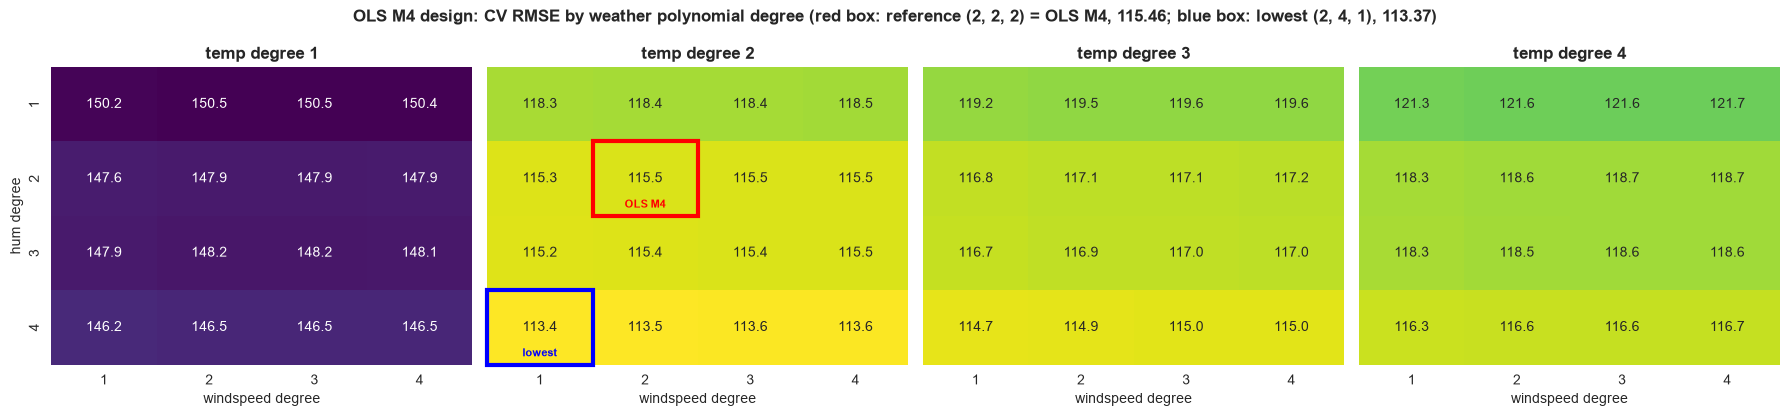

In [3]:
COMBOS = list(product(range(1, 5), repeat=3))
ols_folds = {c: cv_folds('ols', None, c) for c in COMBOS}
rmse = pd.Series({c: summarise(f)['cv_rmse'] for c, f in ols_folds.items()})
rmse.index = pd.MultiIndex.from_tuples(rmse.index, names=['temp', 'hum', 'windspeed'])
best = tuple(int(d) for d in rmse.idxmin())
_, _, gz, nb = paired_gain(ref_ols, ols_folds[best])
print(f"Best combination {best}: CV RMSE {rmse[best]:.2f} | reference (2, 2, 2) = OLS M4: {rmse[REF]:.2f} "
      f"| paired gain {gz:.2f} SE, lower MSE in {nb}/{K} months")

fig, axes = plt.subplots(1, 4, figsize=(18, 4.2), sharey=True)
for ax, t in zip(axes, range(1, 5)):
    grid = rmse.xs(t, level='temp').unstack('windspeed').sort_index()
    sns.heatmap(grid, annot=True, fmt='.1f', cmap='viridis_r', vmin=rmse.min(), vmax=rmse.max(), cbar=False, ax=ax)
    ax.set_title(f'temp degree {t}', fontweight='bold')
    ax.set_xlabel('windspeed degree'); ax.set_ylabel('hum degree' if t == 1 else '')
    for cell, label, colour in [(REF, 'OLS M4', 'red'), (best, 'lowest', 'blue')]:   # outline reference and lowest
        if t == cell[0]:
            r, c = list(grid.index).index(cell[1]), list(grid.columns).index(cell[2])
            ax.add_patch(plt.Rectangle((c, r), 1, 1, fill=False, edgecolor=colour, linewidth=3, clip_on=False))
            ax.text(c + 0.5, r + 0.85, label, ha='center', va='center', fontsize=8, color=colour, fontweight='bold')
fig.suptitle(f'OLS M4 design: CV RMSE by weather polynomial degree (red box: reference (2, 2, 2) = OLS M4, {rmse[REF]:.2f}; '
             f'blue box: lowest {best}, {rmse[best]:.2f})', fontweight='bold')
plt.tight_layout()
plt.show()

### Interpretation & Modeling Decisions: Degree per Weather Variable
**Author**: Lee Sin Yang

<!-- Student commentary here -->

## 3. Ridge and LASSO with Weather Terms up to Degree 4
*Code: Generated by AI Assistant*

All three weather variables up to degree 4 (80 columns) on the M4 design. $\lambda$ is tuned over the Notebook 05 grids and $\lambda_{\min}$ (lowest mean CV MSE, the Notebook 06 rule) is reported. The weather terms are written two ways:
- **raw powers**: powers of the variables as stored (0 to 1 scale), as in Notebooks 04 to 06;
- **orthogonal**: orthogonal polynomials of degree 1 to 4 for each variable (QR decomposition of $[1, x, x^2, x^3, x^4]$ on the fold's training rows, as R's `poly()`), applied to the validation month with the same coefficients. The basis does not change when the variable is shifted or rescaled (checked in Section 1).

OLS on this space gives the same predictions either way, so it is shown once. Gains are paired against the selected LASSO M4 (Notebook 06 winner). The table is charted below and saved to `figures/17_degree4_raw_vs_orthogonal.png`.

In [4]:
DEG4 = (4, 4, 4)
TERMS = {'raw': 'raw powers', 'orthogonal': 'orthogonal'}

jobs = ([(kind, a, DEG4, p) for p in TERMS for kind in ['ridge', 'lasso'] for a in ALPHA_GRIDS[kind]]
        + [('lasso', a, REF, 'raw') for a in ALPHA_GRIDS['lasso']])   # selected spec, full lambda curve for Section 4
pen_folds = dict(zip(jobs, Parallel(n_jobs=-1)(delayed(cv_folds)(*j) for j in jobs)))


def compare(folds):
    g, _, gz, nb = paired_gain(ref_lasso, folds)
    return {**summarise(folds), 'gain_vs_selected_mse': g, 'gain_in_SEs': gz, 'folds_better': f'{nb}/{K}'}


ols4 = cv_folds('ols', None, DEG4)
assert np.allclose(ols4, cv_folds('ols', None, DEG4, 'orthogonal'))   # same OLS predictions under any basis
rows = [{'model': 'LASSO M4 selected (Notebook 06)', 'degrees': REF, 'terms': 'raw powers', 'alpha': ALPHA_SELECTED, **compare(ref_lasso)},
        {'model': 'OLS M4 (Notebook 04)', 'degrees': REF, 'terms': 'raw powers', 'alpha': np.nan, **compare(ref_ols)},
        {'model': 'OLS best per-variable (Section 2)', 'degrees': best, 'terms': 'raw powers', 'alpha': np.nan,
         **compare(ols_folds[best])},
        {'model': 'OLS', 'degrees': DEG4, 'terms': 'either', 'alpha': np.nan, **compare(ols4)}]
ALPHA_MIN = {}
for p, label in TERMS.items():
    for kind in ['ridge', 'lasso']:
        curve = {a: pen_folds[(kind, a, DEG4, p)].mean() for a in ALPHA_GRIDS[kind]}
        ALPHA_MIN[(kind, p)] = a = min(curve, key=curve.get)
        rows.append({'model': 'Ridge' if kind == 'ridge' else 'LASSO', 'degrees': DEG4, 'terms': label, 'alpha': a,
                     **compare(pen_folds[(kind, a, DEG4, p)])})

summary_07 = pd.DataFrame(rows)
pd.set_option('display.width', 200)
print('=== CV comparison (positive gain = lower MSE than the selected LASSO M4) ===')
print(summary_07.round({'alpha': 5, 'cv_rmse': 2, 'se_rmse': 2, 'cv_mse': 0, 'se_mse': 0, 'gain_vs_selected_mse': 0,
                        'gain_in_SEs': 2}).drop(columns=['cv_mse', 'se_mse']).to_string(index=False))

# Orthogonal components kept by LASSO, refitted on the full training set at lambda_min
X = design(DEG4, 'orthogonal', np.arange(len(X_base)))
coef = pd.Series(make_estimator('lasso', ALPHA_MIN[('lasso', 'orthogonal')]).fit(X, np.log(y_all)).named_steps['reg'].coef_, index=X.columns)
kept = {c: [d for d, n in enumerate(col_names(c, 4, 'orthogonal'), start=1) if coef[n] != 0] for c in WEATHER}
print('\nOrthogonal LASSO keeps components:', '; '.join(f"{c} {','.join(map(str, d)) or '-'}" for c, d in kept.items()),
      f'({int((coef != 0).sum())} of {len(coef)} coefficients non-zero)')
print(f"Settings evaluated in this notebook: {len(COMBOS)} OLS degree combinations + {len(jobs)} penalised (model, lambda, terms) settings")

=== CV comparison (positive gain = lower MSE than the selected LASSO M4) ===
                            model   degrees      terms      alpha  cv_rmse  se_rmse  gain_vs_selected_mse  gain_in_SEs folds_better
  LASSO M4 selected (Notebook 06) (2, 2, 2) raw powers    0.00251   110.68    17.90                   0.0          NaN          0/8
             OLS M4 (Notebook 04) (2, 2, 2) raw powers        NaN   115.46    18.95               -1079.0        -1.53          2/8
OLS best per-variable (Section 2) (2, 4, 1) raw powers        NaN   113.37    18.45                -601.0        -1.10          2/8
                              OLS (4, 4, 4)     either        NaN   116.67    21.02               -1361.0        -0.86          3/8
                            Ridge (4, 4, 4) raw powers  630.95734    98.90    12.46                2469.0         1.54          5/8
                            LASSO (4, 4, 4) raw powers    0.01000    90.91     9.21                3986.0         1.69          5/8

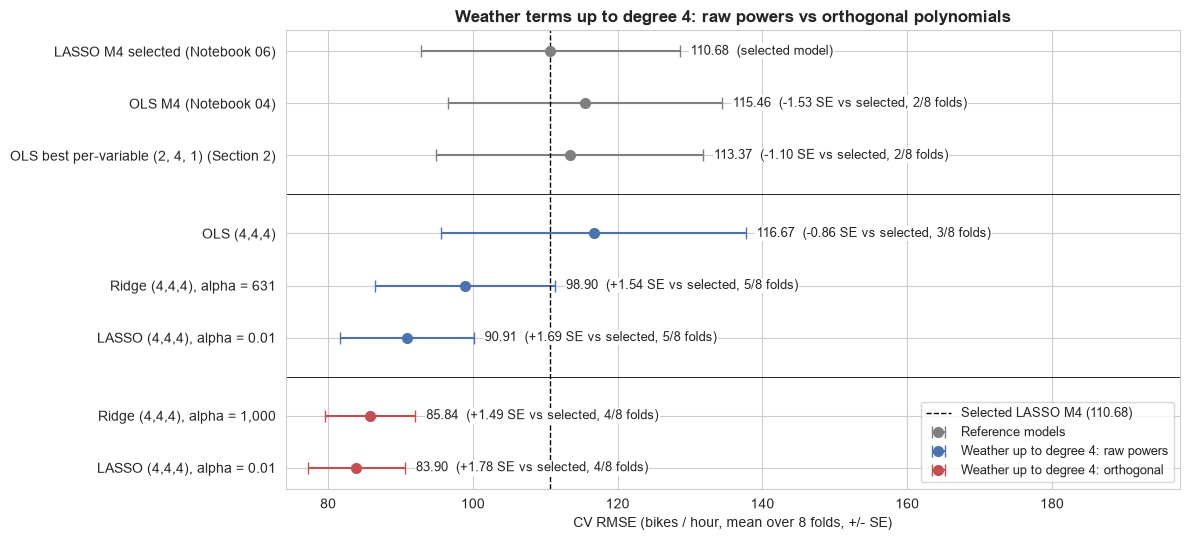

In [5]:
# Chart of the table above: CV RMSE +/- SE, grouped; right-hand text = paired gain vs the selected LASSO M4
GROUPS = [('Reference models', summary_07.index[:3], '#7f7f7f'),
          ('Weather up to degree 4: raw powers', summary_07.index[[3, 4, 5]], '#4c72b0'),
          ('Weather up to degree 4: orthogonal', summary_07.index[[6, 7]], '#c44e52')]


def row_label(r):
    if r['model'].startswith(('LASSO M4 selected', 'OLS M4')):
        return r['model']
    if r['model'].startswith('OLS best'):
        return f"OLS best per-variable {tuple(r['degrees'])} (Section 2)"
    a = ('' if pd.isna(r['alpha']) else
         f", alpha = {r['alpha']:,.0f}" if r['alpha'] >= 1 else f", alpha = {r['alpha']:.3g}")
    return f"{r['model']} (4,4,4){a}"


fig, ax = plt.subplots(figsize=(12, 5.5))
y, ticks, labels = 0, [], []
for g, (group, idx, color) in enumerate(GROUPS):
    if g:
        ax.axhline(y - 0.25, color='black', linewidth=0.6)   # separator between groups
        y += 0.5
    for i, k in enumerate(idx):
        r = summary_07.loc[k]
        ax.errorbar(r['cv_rmse'], y, xerr=r['se_rmse'], fmt='o', color=color, capsize=4, markersize=7,
                    label=group if i == 0 else None)
        note = 'selected model' if k == 0 else f"{r['gain_in_SEs']:+.2f} SE vs selected, {r['folds_better']} folds"
        ax.text(r['cv_rmse'] + r['se_rmse'] + 1.5, y, f"{r['cv_rmse']:.2f}  ({note})", va='center', fontsize=9,
                zorder=5, bbox=dict(facecolor='white', edgecolor='none', pad=1))
        ticks.append(y); labels.append(row_label(r))
        y += 1
ax.axvline(summary_07.loc[0, 'cv_rmse'], color='black', linestyle='--', linewidth=1,
           label=f"Selected LASSO M4 ({summary_07.loc[0, 'cv_rmse']:.2f})")
ax.set_yticks(ticks, labels)
ax.invert_yaxis()
ax.set_xlim(right=(summary_07['cv_rmse'] + summary_07['se_rmse']).max() + 60)
ax.set_xlabel('CV RMSE (bikes / hour, mean over 8 folds, +/- SE)')
ax.set_title('Weather terms up to degree 4: raw powers vs orthogonal polynomials', fontweight='bold')
ax.legend(loc='lower right', fontsize=9)
plt.tight_layout()
plt.savefig(os.path.join('..', 'figures', '17_degree4_raw_vs_orthogonal.png'), dpi=150, bbox_inches='tight')
plt.show()

## 4. Forward-Chained Tuning
*Code: Generated by AI Assistant*

The CV scores above use the same eight folds to choose $\lambda$ and to report the error, so they are optimistic. Following Notebook 05 Section 6b.5, $\lambda$ is chosen here from the earlier validation months only (lowest mean MSE over months $1, \dots, i$) and scored on month $i + 1$, for validation months 3 to 8 (April to September 2012). `fixed_lambda_min` is the same model at its single $\lambda_{\min}$ over the same six months; `optimism_mse` is the difference. OLS M4 needs no tuning and is shown over the same months for reference.

In [6]:
def forward_chained(kind, degrees, terms):
    A = ALPHA_GRIDS[kind]
    M = np.array([pen_folds[(kind, a, degrees, terms)] for a in A])   # alphas x folds
    picks = [M[:, :i].mean(axis=1).argmin() for i in range(2, K)]
    chained = np.array([M[j, i] for j, i in zip(picks, range(2, K))])
    fixed = M[M.mean(axis=1).argmin(), 2:]
    return A[picks], chained, fixed


CHAINED = {'LASSO M4 selected spec': ('lasso', REF, 'raw'),
           'Ridge (4,4,4) orthogonal': ('ridge', DEG4, 'orthogonal'),
           'LASSO (4,4,4) orthogonal': ('lasso', DEG4, 'orthogonal')}
rows = []
for label, spec in CHAINED.items():
    picks, chained, fixed = forward_chained(*spec)
    rows.append({'model': label, 'chained_rmse': np.sqrt(chained.mean()), 'fixed_lambda_min_rmse': np.sqrt(fixed.mean()),
                 'optimism_mse': chained.mean() - fixed.mean(), 'lambda_picks': ', '.join(f'{a:.3g}' for a in picks)})
rows.append({'model': 'OLS M4 (no tuning)', 'chained_rmse': np.sqrt(ref_ols[2:].mean()), 'fixed_lambda_min_rmse': np.nan,
             'optimism_mse': np.nan, 'lambda_picks': ''})
print('Scored months:', ', '.join(VAL_MONTHS[2:]))
print(pd.DataFrame(rows).set_index('model').round(2).to_string())

Scored months: 2012-04, 2012-05, 2012-06, 2012-07, 2012-08, 2012-09
                          chained_rmse  fixed_lambda_min_rmse  optimism_mse                                      lambda_picks
model                                                                                                                        
LASSO M4 selected spec          134.65                 123.37       2911.41        0.00126, 0.00178, 0.0141, 0.02, 0.02, 0.02
Ridge (4,4,4) orthogonal        105.36                  85.89       3724.74             63.1, 158, 1e+03, 1e+03, 1e+03, 1e+03
LASSO (4,4,4) orthogonal        107.49                  88.59       3705.16  0.00126, 0.00251, 0.0141, 0.0141, 0.0141, 0.0141
OLS M4 (no tuning)              129.07                    NaN           NaN                                                  


### Interpretation & Modeling Decisions: Penalised Models and Forward-Chained Tuning
**Author**: Lee Sin Yang

<!-- Student commentary here -->

## 5. Residuals by Weather Variable
*Code: Generated by AI Assistant*

Compares the selected LASSO M4 (weather squared) with LASSO M4 using orthogonal weather terms up to degree 4 (4, 4, 4), each at its $\lambda_{\min}$. Residuals are **out-of-fold**: for each of the eight CV folds the model is fitted on the training window and predicts its validation month, so every residual comes from a month the model was not fitted on (Feb – Sep 2012). Residual = actual − predicted rentals per hour (count scale, after back-transformation). Hours are grouped into bins of each weather variable (temperature 3 °C, humidity 10%, wind speed 4 km/h; bins with fewer than 30 hours are dropped); each point is the bin's mean residual with a 95% confidence interval. A model with no leftover weather pattern has points scattered around 0 with no trend. Saved to `figures/11_weather_residuals_oof.png`.

Selected LASSO M4, weather squared: RMSE pooled over all 5,825 validation hours = 111.18 (CV RMSE averages fold MSEs, so differs slightly) | mean residual = -39.1
LASSO M4, weather up to degree 4 (orthogonal): RMSE pooled over all 5,825 validation hours = 84.16 (CV RMSE averages fold MSEs, so differs slightly) | mean residual = -3.7


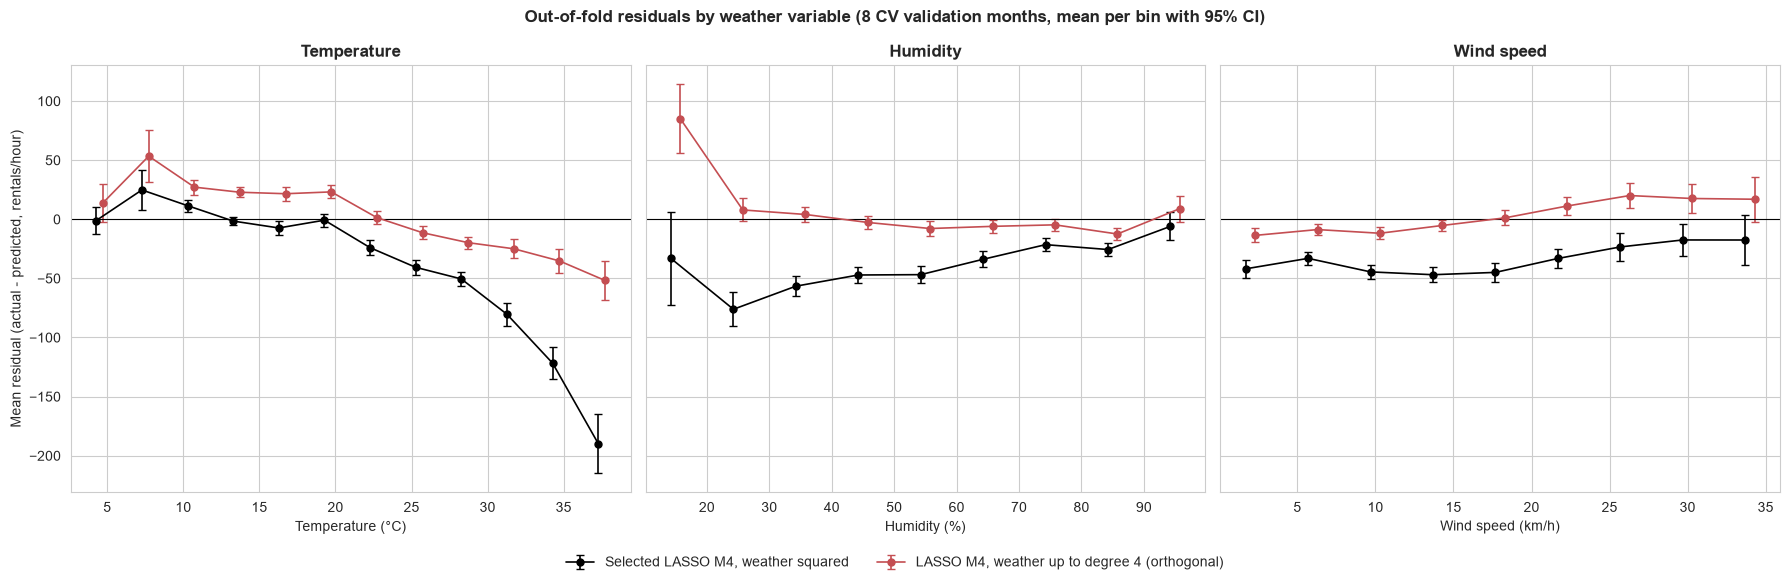

                                                         bins  largest |bin mean residual|  hour-weighted mean |bin mean residual|
variable  model                                                                                                                   
temp      Selected LASSO M4, weather squared               12                        189.8                                    39.8
          LASSO M4, weather up to degree 4 (orthogonal)    12                         53.4                                    19.0
hum       Selected LASSO M4, weather squared                9                         76.1                                    39.1
          LASSO M4, weather up to degree 4 (orthogonal)     9                         85.1                                     7.0
windspeed Selected LASSO M4, weather squared                9                         46.9                                    39.7
          LASSO M4, weather up to degree 4 (orthogonal)     9                      

In [7]:
UNITS = {'temp': (41.0, 'Temperature (°C)', np.arange(0, 45, 3)),
         'hum': (100.0, 'Humidity (%)', np.arange(0, 110, 10)),
         'windspeed': (67.0, 'Wind speed (km/h)', np.arange(-0.01, 64, 4))}
MIN_N = 30
MODELS = [   # (label, (kind, alpha, degrees, terms), colour)
    ('Selected LASSO M4, weather squared', ('lasso', ALPHA_SELECTED, REF, 'raw'), 'black'),
    ('LASSO M4, weather up to degree 4 (orthogonal)', ('lasso', ALPHA_MIN[('lasso', 'orthogonal')], DEG4, 'orthogonal'), '#c44e52'),
]
VAL_ROWS = np.concatenate([va for _, va in FOLDS])


def oof_predictions(kind, alpha, degrees, terms):
    # Count-scale predictions for every validation row, each from the model fitted on that fold's training window
    pred = np.empty(len(X_base))
    for tr, va in FOLDS:
        X = design(degrees, terms, tr)
        pred[va], _ = fit_predict_count(kind, alpha, X.iloc[tr], y_all[tr], X.iloc[va])
    return pred[VAL_ROWS]


resid = {label: y_all[VAL_ROWS] - oof_predictions(*spec) for label, spec, _ in MODELS}
for label, r in resid.items():
    print(f"{label}: RMSE pooled over all {len(r):,} validation hours = {np.sqrt(np.mean(r ** 2)):.2f} "
          f"(CV RMSE averages fold MSEs, so differs slightly) | mean residual = {r.mean():.1f}")

fig, axes = plt.subplots(1, 3, figsize=(18, 5.5), sharey=True)
summary_rows = []
for j, (ax, var) in enumerate(zip(axes, WEATHER)):
    scale, xlabel, bins = UNITS[var]
    x = X_base[var].to_numpy()[VAL_ROWS] * scale
    groups = pd.cut(x, bins)
    for k, (label, _, color) in enumerate(MODELS):
        g = pd.Series(resid[label]).groupby(groups, observed=True).agg(['mean', 'std', 'count'])
        g = g[g['count'] >= MIN_N]
        centre = np.array([iv.mid for iv in g.index]) + (k - 0.5) * (bins[1] - bins[0]) * 0.15
        ax.errorbar(centre, g['mean'], yerr=1.96 * g['std'] / np.sqrt(g['count']), fmt='o-', color=color,
                    capsize=3, markersize=5, linewidth=1.2, label=label if j == 0 else None)
        summary_rows.append({'variable': var, 'model': label, 'bins': len(g),
                             'largest |bin mean residual|': g['mean'].abs().max(),
                             'hour-weighted mean |bin mean residual|': np.average(g['mean'].abs(), weights=g['count'])})
    ax.axhline(0, color='black', linewidth=0.8)
    ax.set_xlabel(xlabel)
    ax.set_title(xlabel.split(' (')[0], fontweight='bold')
axes[0].set_ylabel('Mean residual (actual - predicted, rentals/hour)')
fig.legend(loc='lower center', ncol=2, fontsize=10, bbox_to_anchor=(0.5, -0.06), frameon=False)
fig.suptitle('Out-of-fold residuals by weather variable (8 CV validation months, mean per bin with 95% CI)',
             fontweight='bold')
plt.tight_layout()
plt.savefig(os.path.join('..', 'figures', '11_weather_residuals_oof.png'), dpi=150, bbox_inches='tight')
plt.show()
print(pd.DataFrame(summary_rows).set_index(['variable', 'model']).round(1).to_string())

### Interpretation & Modeling Decisions: Post-Hoc Sensitivity Analysis Summary
**Author**: Lee Sin Yang

<!-- Student commentary here -->